# DG-TSK: gates that select features and rules

This notebook follows, one step at a time, the classifier of

> G. Xue, J. Wang, B. Zhang, B. Yuan and C. Dai, "Double groups of gates based
> Takagi-Sugeno-Kang (DG-TSK) fuzzy system for simultaneous feature selection and rule
> extraction", *Fuzzy Sets and Systems*, vol. 469, 2023.

on Wine, one of the datasets of the article. DG-TSK starts from a rule base with one rule
per training sample, trains a gate for every feature and for every rule, and keeps the
features and rules whose gates open. The notebook is a short version of the script
`examples/reproductions/dgtsk_2023.py`, which runs three datasets with ten folds repeated
ten times; here one repetition on one dataset runs in a few minutes.

1. settings and reproducibility;
2. the data;
3. the rule base before training;
4. DG-TSK on one fold;
5. how long to train the gates;
6. what the fitted model looks like;
7. ten folds, next to the article.

## 1. Settings and reproducibility

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import torch
from sklearn.datasets import load_wine
from sklearn.model_selection import StratifiedKFold
from sklearn.preprocessing import MinMaxScaler

import highfis
from highfis import DGTSKClassifier
from highfis.memberships import GaussianMF
from highfis.models import TSKClassifierModel

In [2]:
SEED = 0
FOLDS = 10
THREADS = 1
GATE_ITERATIONS = 1000

# The article on Wine: Table 2, the rule base without training (accuracy in percent), and
# Table 3, DG-TSK (accuracy, selected features, extracted rules).
ARTICLE_UNTRAINED = 96.63
ARTICLE = (98.3, 8.0, 3.0)

torch.set_num_threads(THREADS)
torch.use_deterministic_algorithms(True)
highfis.set_mf_cache_enabled(False)

## 2. The data

Wine has 178 samples of three cultivars, described by 13 chemical measurements.

In [3]:
wine = load_wine()
features, labels, feature_names = wine.data, wine.target, wine.feature_names
n_classes = int(labels.max()) + 1

print(f"{features.shape[0]} samples, {features.shape[1]} features, {n_classes} classes")

178 samples, 13 features, 3 classes


The first of ten folds is followed in detail. The article scales the inputs to [0, 1],
with the range of the training part.

In [4]:
folds = StratifiedKFold(n_splits=FOLDS, shuffle=True, random_state=SEED)
train, test = next(folds.split(features, labels))

scaler = MinMaxScaler().fit(features[train])
x_train = scaler.transform(features[train]).astype(np.float32)
x_test = scaler.transform(features[test]).astype(np.float32)
y_train, y_test = labels[train], labels[test]

print(f"training: {len(x_train)} samples, test: {len(x_test)} samples")

training: 160 samples, test: 18 samples


## 3. The rule base before training

The article starts from **one rule per training sample**. For every feature, the rule has
a Gaussian fuzzy set centred on the value of the sample; all sets share one spread, the
mean of the standard deviations of the features. The consequent of the rule is the label
of the sample. Nothing is trained: the system answers with the labels of the training
samples that are close to the input.

In [5]:
spread = float(np.std(x_train, axis=0, ddof=1).mean())
fuzzy_sets = {
    f"x{d}": [GaussianMF(mean=float(centre), sigma=spread) for centre in x_train[:, d]]
    for d in range(x_train.shape[1])
}
rule_base = TSKClassifierModel(fuzzy_sets, n_classes=n_classes, rule_base="coco")
with torch.no_grad():
    rule_base.consequent_layer.weight.zero_()
    rule_base.consequent_layer.bias.copy_(torch.eye(n_classes)[torch.as_tensor(y_train)])
    predicted = rule_base(torch.as_tensor(x_test)).argmax(dim=1).numpy()

print(f"common spread: {spread:.3f}")
print(f"rules: {rule_base.n_rules}, each with {x_train.shape[1]} conditions")
print(f"test accuracy without training: {100 * np.mean(predicted == y_test):.1f}%")

common spread: 0.201
rules: 160, each with 13 conditions
test accuracy without training: 100.0%


It is accurate, but it has 160 rules of 13 conditions each. DG-TSK reduces both.

## 4. DG-TSK on one fold

Two groups of gates are trained on that rule base, one gate per feature and one per rule.
The features and rules whose gates stay below a threshold are removed, and the remaining
system is fine-tuned. The defaults of `DGTSKClassifier` are the settings of the article;
the gates are trained here for 1000 iterations.

In [6]:
model = DGTSKClassifier(dg_epochs=GATE_ITERATIONS, random_state=SEED).fit(x_train, y_train)

print(f"test accuracy: {100 * model.score(x_test, y_test):.1f}%")
print(f"selected features: {len(model.selected_features_)} of {x_train.shape[1]}")
print(f"extracted rules: {model.model_.n_rules} of {x_train.shape[0]}")
print([feature_names[d] for d in model.selected_features_])

test accuracy: 100.0%
selected features: 10 of 13
extracted rules: 3 of 160
['alcohol', 'malic_acid', 'ash', 'alcalinity_of_ash', 'magnesium', 'flavanoids', 'color_intensity', 'hue', 'od280/od315_of_diluted_wines', 'proline']


The training loss of the two phases, one after the other:

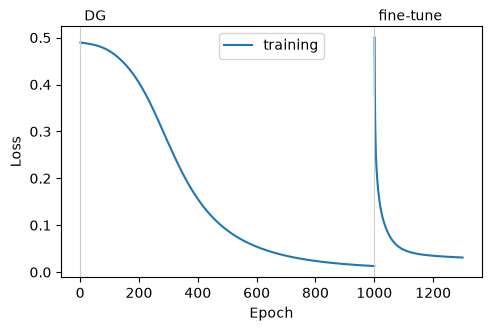

In [7]:
model.plot_history()
plt.show()

The gates of the selected features and of the extracted rules at the end of the gate
phase, with the thresholds they passed. The features are numbered from one, in the order
of the columns of the data:

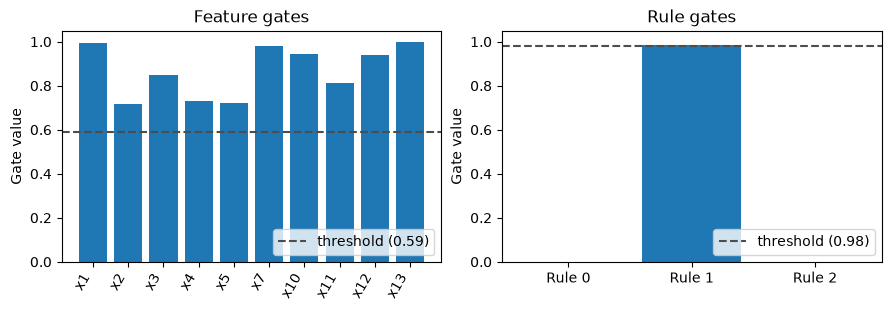

In [8]:
model.plot_gates()
plt.show()

## 5. How long to train the gates

The gates start almost closed and keep opening as the phase goes on, so its length
decides how many features pass the threshold. The article states 300 iterations for one
of its experiments and does not state the number behind its table of results; 300 is the
default of the estimator. On this fold:

In [9]:
lengths = [100, 300, 600, 1000, 2000]
kept, accuracy = [], []
for length in lengths:
    fitted = DGTSKClassifier(dg_epochs=length, random_state=SEED).fit(x_train, y_train)
    kept.append(len(fitted.selected_features_))
    accuracy.append(100 * fitted.score(x_test, y_test))
    print(f"{length:5d} iterations: {kept[-1]:2d} features, {fitted.model_.n_rules} rules, test accuracy {accuracy[-1]:.1f}%")

  100 iterations:  3 features, 3 rules, test accuracy 94.4%


  300 iterations:  5 features, 3 rules, test accuracy 100.0%


  600 iterations:  8 features, 3 rules, test accuracy 100.0%


 1000 iterations: 10 features, 3 rules, test accuracy 100.0%


 2000 iterations: 12 features, 3 rules, test accuracy 100.0%


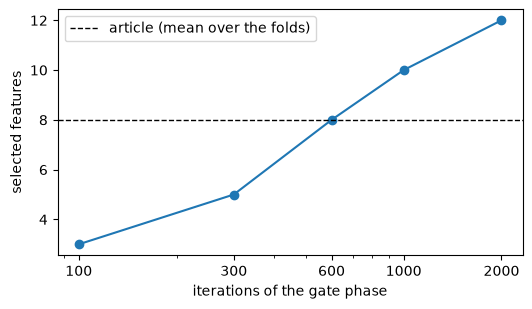

In [10]:
fig, ax = plt.subplots(figsize=(6, 3.2))
ax.plot(lengths, kept, "o-")
ax.axhline(ARTICLE[1], color="black", linestyle="--", linewidth=1, label="article (mean over the folds)")
ax.set_xscale("log")
ax.set_xticks(lengths, [str(length) for length in lengths])
ax.set_xlabel("iterations of the gate phase")
ax.set_ylabel("selected features")
ax.legend()
plt.show()

With 1000 iterations the number of selected features is close to the one of the article,
which is why the reproduction uses that length.

## 6. What the fitted model looks like

The model of section 4 has three rules on the selected features. Its confusion matrix on
the 18 test samples, with the margin of each decision:

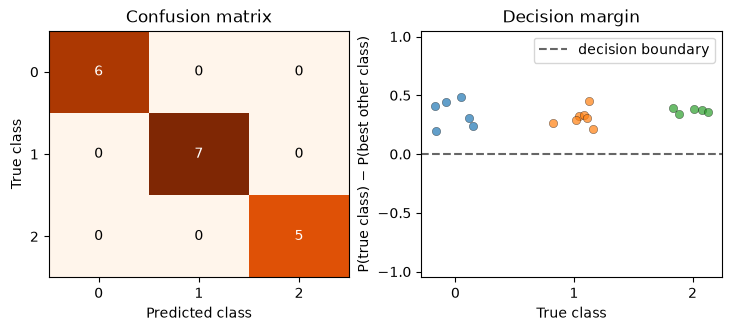

In [11]:
model.plot_diagnostics(x_test, y_test)
plt.show()

The three rules came from three training samples. The mean weight of each rule on the
test samples of each class shows how they share the input space; where one rule covers
two classes, its first-order consequent separates them:

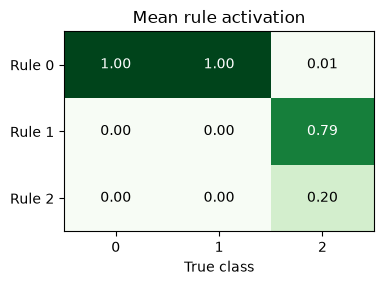

In [12]:
fig, ax = plt.subplots(figsize=(4, 2.6))
model.plot_rule_activation(x_test, y_test, ax=ax)
plt.show()

The fuzzy sets of four of the selected features, after fine-tuning:

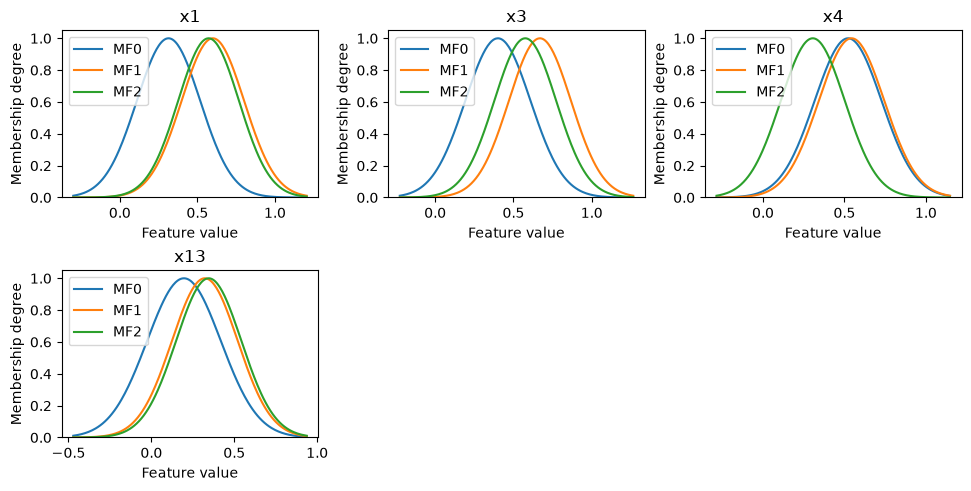

In [13]:
model.plot_memberships(max_features=4)
plt.show()

The rules as sentences, with the three features that weigh most in each consequent:

In [14]:
print(model.rules_as_text(top_features=3))

Rule 0: IF x1 is low AND x4 is medium AND x13 is low AND ... (7 more)
        THEN 0: -0.37 + 0.82 * x13 + 0.61 * x1 - 0.49 * x4 + ...
             1: 1.07 - 0.85 * x13 + 0.62 * x4 - 0.55 * x1 + ...
             2: -0.00 + 0.03 * x12 - 0.02 * x10 - 0.02 * x13 + ...
Rule 1: IF x1 is high AND x4 is high AND x13 is medium AND ... (7 more)
        THEN 0: -0.01 + 0.02 * x10 - 0.01 * x12 - 0.01 * x11 + ...
             1: -0.01 + 0.03 * x7 - 0.01 * x2 + 0.01 * x10 + ...
             2: 0.47 + 0.20 * x3 + 0.18 * x4 + 0.16 * x1 + ...
Rule 2: IF x1 is medium AND x4 is low AND x13 is high AND ... (7 more)
        THEN 0: -0.01 - 0.01 * x4 + 0.01 * x13 + 0.01 * x1 + ...
             1: 0.02 + 0.03 * x7 + 0.03 * x12 + 0.02 * x11 + ...
             2: 0.42 + 0.22 * x3 + 0.20 * x4 + 0.20 * x2 + ...


A summary of the model and of its training, in one call:

In [15]:
print(model.summary())

DGTSKClassifier
  task               classification, 3 classes
  features           13 seen in fit, 10 used by the model
  rules              3 (rule base: pfrb)
  fuzzy sets         3 per feature, GaussianMF
  firing strength    DGTSKRuleLayer
  defuzzifier        SoftmaxLogDefuzzifier
  consequents        GatedClassificationConsequentLayer
  parameters         202 trainable (60 antecedent, 132 consequent)
Training (full batch)
  phase        epochs  rate  loss first -> last  accuracy
  gates          1000   0.2    0.4894 -> 0.0128    0.9937
  fine-tuning     300   0.2    0.5000 -> 0.0311    0.9937


How the rules produce the prediction of the first test sample. The output is the sum of
what each rule contributes, and the predicted class is the one with the largest value:

In [16]:
print(model.explain(x_test[0]))

Prediction: 0
Output, the sum of the contributions of the 3 rules: 0: +1.26, 1: -0.26, 2: -0.01
Rule 0, weight 0.99: contributes 0: +1.26, 1: -0.26, 2: -0.03
    IF x1 is low AND x4 is medium AND x13 is low AND ... (7 more)
Rule 1, weight 0.01: contributes 0: -0.00, 1: +0.00, 2: +0.01
    IF x1 is high AND x4 is high AND x13 is medium AND ... (7 more)
Rule 2, weight 0.01: contributes 0: -0.00, 1: +0.00, 2: +0.01
    IF x1 is medium AND x4 is low AND x13 is high AND ... (7 more)


How well the rules cover the samples: for each sample, the mean membership degree in its
best-matching rule. A test sample with a coverage well below the training samples would
lie outside the region the rules were built on:

In [17]:
inside, outside = model.coverage(x_train), model.coverage(x_test)
print(f"training part: min {inside.min():.2f}, median {np.median(inside):.2f}")
print(f"test part:     min {outside.min():.2f}, median {np.median(outside):.2f}")

training part: min 0.48, median 0.74
test part:     min 0.55, median 0.76


## 7. Ten folds, next to the article

In [18]:
runs, selections, untrained = [], [], []

for train, test in StratifiedKFold(n_splits=FOLDS, shuffle=True, random_state=SEED).split(features, labels):
    scaler = MinMaxScaler().fit(features[train])
    a_train = scaler.transform(features[train]).astype(np.float32)
    a_test = scaler.transform(features[test]).astype(np.float32)

    fitted = DGTSKClassifier(dg_epochs=GATE_ITERATIONS, random_state=SEED).fit(a_train, labels[train])
    runs.append((100 * fitted.score(a_test, labels[test]), len(fitted.selected_features_), fitted.model_.n_rules))
    selections.append(fitted.selected_features_)

runs = np.asarray(runs)
print(f"{'':10s} {'accuracy':>9s} {'features':>9s} {'rules':>6s}")
print(f"{'article':10s} {ARTICLE[0]:9.1f} {ARTICLE[1]:9.1f} {ARTICLE[2]:6.1f}")
print(f"{'highFIS':10s} {runs[:, 0].mean():9.1f} {runs[:, 1].mean():9.1f} {runs[:, 2].mean():6.1f}")

            accuracy  features  rules
article         98.3       8.0    3.0
highFIS         98.3       9.7    3.0


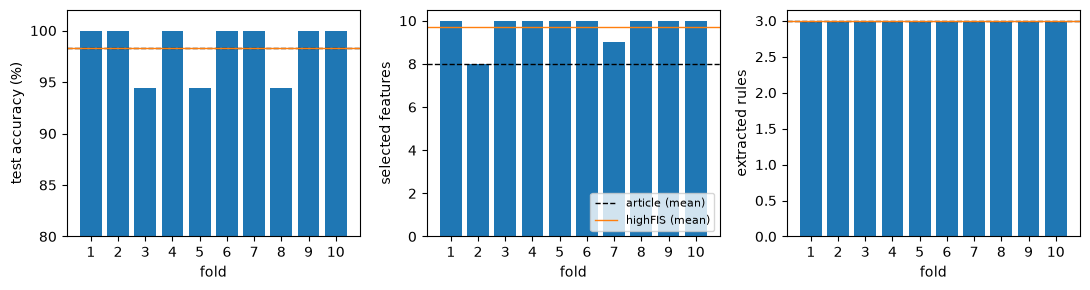

In [19]:
LOWER = 80

fig, axes = plt.subplots(1, 3, figsize=(11, 3))
folds_axis = np.arange(1, FOLDS + 1)
for ax, column, label, reported in zip(axes, range(3), ["test accuracy (%)", "selected features", "extracted rules"], ARTICLE):
    ax.bar(folds_axis, runs[:, column])
    ax.axhline(reported, color="black", linestyle="--", linewidth=1, label="article (mean)")
    ax.axhline(runs[:, column].mean(), color="tab:orange", linewidth=1, label="highFIS (mean)")
    ax.set_xticks(folds_axis)
    ax.set_xlabel("fold")
    ax.set_ylabel(label)
axes[0].set_ylim(LOWER, 102)
axes[1].legend(fontsize=8, loc="lower right")
plt.tight_layout()
plt.show()

How often each feature is selected over the ten folds:

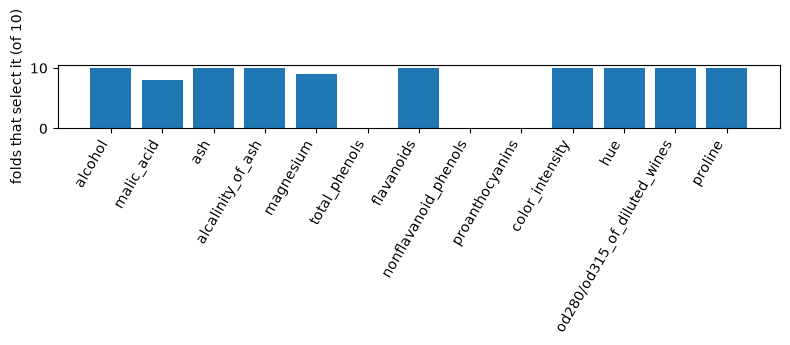

In [20]:
frequency = np.bincount(np.concatenate(selections), minlength=features.shape[1])

fig, ax = plt.subplots(figsize=(8, 3))
ax.bar(range(len(frequency)), frequency)
ax.set_xticks(range(len(frequency)), feature_names, rotation=60, ha="right")
ax.set_ylabel(f"folds that select it (of {FOLDS})")
plt.tight_layout()
plt.show()

The same features come back in most folds. The script repeats the ten folds ten times, as
the article does, and also runs Iris and Glass; over the 100 runs Wine gives 97.2% with
9.5 features and 3.0 rules.